# 01 · Startup success model, baseline + human in the loop


**問題** 只用「種子輪當下」看得到的資訊，能不能預測一家公司之後會走到 Series B 以上、被收購或 IPO？
**再加上** 模型做不到的人的判斷（團隊、市場野心、moat），怎麼放回流程裡？

資料 [notpeter/crunchbase-data](https://github.com/notpeter/crunchbase-data)（Crunchbase 2015 年公開匯出，舊資料，只當練習用）

## 1. 載入資料
📖 **為什麼** 四張表，companies 是公司，rounds 是每一輪募資，investments 是哪個投資人投了哪一輪，acquisitions 是收購。先全部讀進來看大小。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path('../data/raw')  # 原始資料放在 6. data
FIG_DIR = Path('../figures')  # 圖存到 QA 附件，Obsidian 頁會嵌入
FIG_DIR.mkdir(parents=True, exist_ok=True)

companies = pd.read_csv(DATA_DIR / 'companies.csv')  # 每列一家公司
rounds = pd.read_csv(DATA_DIR / 'rounds.csv', parse_dates=['funded_at'],
                     date_format='%Y-%m-%d')  # 每列一輪募資
investments = pd.read_csv(DATA_DIR / 'investments.csv',
                          parse_dates=['funded_at'],
                          date_format='%Y-%m-%d')  # 每列一個投資人×一輪

for table_name, table in [('companies', companies), ('rounds', rounds),
                          ('investments', investments)]:
    print(table_name, table.shape)  # 列數、欄數

companies (66368, 14)
rounds (114949, 12)
investments (168647, 18)


👀 **結果** 約 6.6 萬家公司、11 萬輪、17 萬筆投資紀錄。量夠做練習，但這是 2015 年的快照，之後發生的事一律看不到。

## 2. 選 cohort，定義「成功」
📖 **為什麼** 這是整個模型最重要的決定（你的 §5「能不能回本整個基金」）。
- **Cohort** 第一輪是 seed 或 angel，而且在 2007–2011 之間，這樣到 2015 至少有 3–4 年讓結果發生。
- **成功 (y=1)** 之後拿到 Series B 以上的輪、或被收購、或 IPO。
- ⚠️ 這比「回本整個基金」寬鬆很多，真正的 unicorn 在這份資料裡太少，模型學不到。

In [2]:
rounds = rounds.dropna(subset=['funded_at'])
rounds = rounds.sort_values('funded_at')

# 每家公司的第一輪
first_round = rounds.groupby('company_permalink').first()

is_early_type = first_round['funding_round_type'].isin(['seed', 'angel'])
in_window = first_round['funded_at'].dt.year.between(2007, 2011)
cohort = first_round[is_early_type & in_window].copy()

# 成功標記一，之後有 Series B 以上的 venture 輪
late_codes = ['B', 'C', 'D', 'E', 'F', 'G', 'H']
late_rounds = rounds[rounds['funding_round_code'].isin(late_codes)]
reached_series_b = set(late_rounds['company_permalink'])

# 成功標記二，被收購或 IPO
status_by_company = companies.set_index('permalink')['status']
exited = set(status_by_company[status_by_company.isin(['acquired', 'ipo'])]
             .index)

cohort['success'] = [
    int(permalink in reached_series_b or permalink in exited)
    for permalink in cohort.index
]
print('cohort size', len(cohort))
print('success rate', round(cohort['success'].mean(), 3))

cohort size 7038
success rate 0.192


👀 **結果** 7038 家公司符合 cohort，其中 **19.2%** 算成功。所以 5 家裡大約 1 家，模型要打敗的基準就是這個比例。

## 3. 特徵，只用種子輪當下看得到的東西
📖 **為什麼** 防 data leakage，所有特徵都只能用第一輪那天以前就知道的資訊。
- 第一輪金額、類型、年份
- 國家（你的「瑞士」論點，是不是美國/英國/德國/法國）
- 產業類別（取最常見的 15 類）
- **投資人經驗** 第一輪的投資人「在那天以前」投過幾家，這是 VC 品質的代理變數，只算過去所以不洩漏

In [3]:
features = pd.DataFrame(index=cohort.index)
features['log_first_amount'] = np.log1p(cohort['raised_amount_usd'].fillna(0))
features['amount_missing'] = cohort['raised_amount_usd'].isna().astype(int)
features['is_angel'] = (cohort['funding_round_type'] == 'angel').astype(int)
features['first_year'] = cohort['funded_at'].dt.year

big_markets = ['USA', 'GBR', 'DEU', 'FRA']  # 你文章 §7.2 點名的大市場
features['big_market_hq'] = cohort['company_country_code'].isin(
    big_markets).astype(int)

main_category = cohort['company_category_list'].fillna('Unknown').str.split(
    '|').str[0]
top_categories = main_category.value_counts().index[:15]
main_category = main_category.where(main_category.isin(top_categories),
                                    'Other')
features = features.join(pd.get_dummies(main_category, prefix='cat',
                                        dtype=int))

# 投資人經驗，每筆投資算該投資人在這之前已經投過幾次
investments = investments.dropna(subset=['funded_at']).sort_values(
    'funded_at')
investments['prior_deals'] = investments.groupby(
    'investor_permalink').cumcount()  # 0 代表這是他第一筆

first_round_ids = set(cohort['funding_round_permalink'])
seed_investments = investments[
    investments['funding_round_permalink'].isin(first_round_ids)
]
investor_stats = seed_investments.groupby('company_permalink').agg(
    n_investors=('investor_permalink', 'nunique'),
    max_investor_prior_deals=('prior_deals', 'max'),
)
features = features.join(investor_stats).fillna(0)
features['log_max_investor_prior'] = np.log1p(
    features.pop('max_investor_prior_deals'))
print(features.shape)
features.head()

(7038, 23)

,log_first_amount,amount_missing,is_angel,first_year,big_market_hq,cat_Advertising,cat_Analytics,cat_Android,cat_Apps,cat_Biotechnology,...,cat_Enterprise Software,cat_Finance,cat_Games,cat_Mobile,cat_Other,cat_Social Media,cat_Software,cat_Unknown,n_investors,log_max_investor_prior
company_permalink,,,,,,,,,,,,,,,,,,,,,
/organization/0ndine-biomedical-inc,10.677316,0,0,2009,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0.0,0.000000
/organization/1,13.815562,0,0,2011,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,8.0,5.521461
/organization/1000-corks,10.596660,0,0,2011,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1.0,4.317488
/organization/1000-markets,13.122365,0,0,2009,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,3.0,3.891820
/organization/1000chi,17.597968,0,1,2010,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1.0,0.000000


👀 **結果** 每家公司一列、約 25 個欄位。⚠️ **團隊這一項完全沒有**，Crunchbase 公開匯出不含創辦人。這正是要靠 human in the loop 補的地方（§6）。

## 4. Baseline 模型
📖 **為什麼** 先用兩個簡單模型。成功是少數類，所以看 **PR-AUC**（average precision），並跟「隨便猜」的基準（= 成功率）比。用時間切分，2007–2010 訓練、2011 測試，模擬「用過去預測未來」。

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

is_train = features['first_year'] <= 2010  # 時間切分，不隨機切
x_train, x_test = features[is_train], features[~is_train]
y_train = cohort.loc[is_train, 'success']
y_test = cohort.loc[~is_train, 'success']

models = {
    'logistic': make_pipeline(StandardScaler(),
                              LogisticRegression(max_iter=2000)),
    'boosted_trees': HistGradientBoostingClassifier(max_iter=300,
                                                     learning_rate=0.05),
}
test_scores = {}
for model_name, model in models.items():
    model.fit(x_train, y_train)
    test_scores[model_name] = model.predict_proba(x_test)[:, 1]
    print(model_name,
          'ROC-AUC', round(roc_auc_score(y_test, test_scores[model_name]), 3),
          'PR-AUC', round(average_precision_score(
              y_test, test_scores[model_name]), 3))
print('random baseline PR-AUC', round(y_test.mean(), 3))

logistic ROC-AUC 0.753 PR-AUC 0.362


boosted_trees ROC-AUC 0.728 PR-AUC 0.324
random baseline PR-AUC 0.15


👀 **結果** 測試集（2011 cohort）上 logistic **PR-AUC 0.362**、boosted trees 0.324，隨便猜是 0.15。==🟢 模型大約比亂猜好 2.4 倍==，但離「看得準」很遠。簡單的 logistic 反而贏，代表訊號主要是幾個單純的線性關係，資料不足以撐起複雜模型。

## 5. 哪些特徵在推動預測
📖 **為什麼** 用 permutation importance，打亂某一欄看分數掉多少，掉越多代表越重要。這比樹模型內建的 importance 誠實。

cat_Mobile                0.0018
amount_missing            0.0021
big_market_hq             0.0104
n_investors               0.0285
log_max_investor_prior    0.0608
log_first_amount          0.0647
dtype: float64


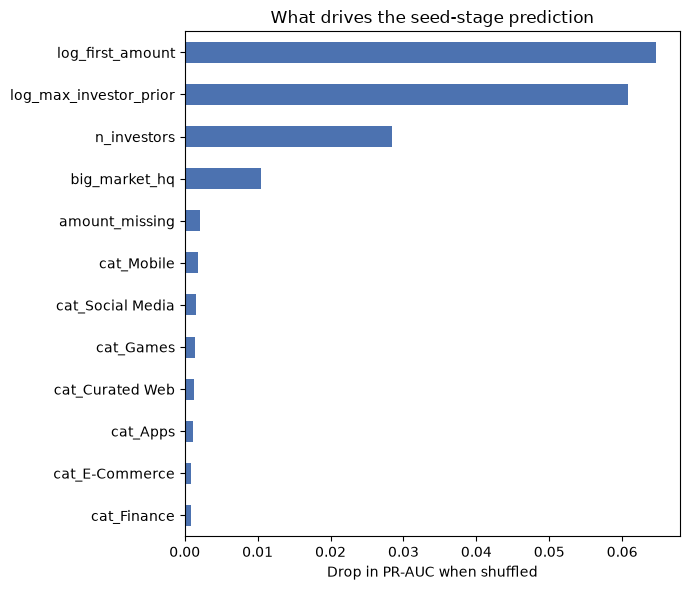

In [5]:
from sklearn.inspection import permutation_importance

booster = models['boosted_trees']
importance = permutation_importance(booster, x_test, y_test,
                                    scoring='average_precision',
                                    n_repeats=10, random_state=0)
importance_table = pd.Series(importance.importances_mean,
                             index=x_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
importance_table.tail(12).plot.barh(ax=ax, color='#4C72B0')
ax.set_title('What drives the seed-stage prediction')
ax.set_xlabel('Drop in PR-AUC when shuffled')
fig.tight_layout()
fig.savefig(FIG_DIR / 'startup_feature_importance.png', dpi=150)
print(importance_table.tail(6).round(4))

👀 **結果** 最重要的兩個是**第一輪金額**（0.065）和**投資人過去經驗**（0.061），其次是投資人數量。也就是說，模型主要學到的是「誰投了你、投多少」，這是別的投資人的判斷，不是公司本身的品質。總部在大市場只有 0.010。⚠️ 這就是 self-fulfilling 的問題，好 VC 投了會讓下一輪更容易募到。

## 6. Human in the loop
📖 **為什麼** 你說得對，VC 很大一部分是人的判斷。模型只看得到數字，看不到 §7.1 團隊、§7.2 野心、§7.3 moat。設計分三層。

1. **模型篩選 (triage)** 模型先給每家公司一個機率。
2. **人只看最需要看的** 機率在中間、模型最不確定的公司優先送給人評，這叫 uncertainty sampling（active learning 的一種）。很高或很低的模型自己就夠了。
3. **人評分 → 合併** 人用你文章三個標準各打 1–5 分，轉成 likelihood ratio 去更新模型的 odds，最後分數 = 模型 prior × 人的證據。人評的結果存成 CSV，累積夠了就變成新的訓練特徵，模型會越來越學會人看到的東西。

❗ ==🔴**YOU DECIDE** 權重 `HUMAN_WEIGHT`，目前 1.0 代表人和模型一樣重要，這是假設，沒有資料驗證過。==

In [6]:
from tqdm.auto import tqdm

test_table = cohort.loc[~is_train, ['company_country_code']].copy()
test_table['name'] = companies.set_index('permalink').reindex(
    test_table.index)['name']
test_table['model_prob'] = test_scores['boosted_trees']

# 不確定性，越接近 0.5 越不確定
test_table['uncertainty'] = 1 - 2 * (test_table['model_prob'] - 0.5).abs()
review_queue = test_table.sort_values('uncertainty', ascending=False).head(20)

# 匯出人評表格，三欄空白給她填 1-5 分
score_sheet = review_queue[['name', 'model_prob']].copy()
for criterion in ['team_outlier_1to5', 'path_to_large_1to5',
                  'moat_1to5', 'notes']:
    score_sheet[criterion] = ''
sheet_path = Path('../data/human_review_queue.csv')
score_sheet.to_csv(sheet_path)
print('review queue saved to', sheet_path)
review_queue[['name', 'model_prob', 'uncertainty']].head(10).round(3)

review queue saved to ..\6. data\human_review_queue.csv


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,name,model_prob,uncertainty
company_permalink,,,
/organization/nexercise,Nexercise,0.500,1.000
/organization/weddinglovely,WeddingLovely,0.500,0.999
/organization/xydo,Curate.me,0.499,0.998
/organization/nanomech,Nanomech,0.498,0.997
/organization/spillnow,Spill Inc,0.498,0.996
/organization/knowlarity-communications,Knowlarity Communications,0.497,0.993
/organization/quisk,Quisk,0.497,0.993
/organization/blu-homes,Blu Homes,0.503,0.993
/organization/attachments-me,Attachments.me,0.505,0.990


👀 **結果** 前 20 家最不確定的公司已經存成 `6. data/human_review_queue.csv`。打開它、查每家公司、填三欄分數，就是人在迴圈裡的那一步。

In [7]:
HUMAN_WEIGHT = 1.0  # 人的證據要多重，見上方 YOU DECIDE


def combine_model_and_human(model_prob, team, path, moat,
                            weight=HUMAN_WEIGHT):
    """用人評分數更新模型機率，回傳合併後的機率。

    :param model_prob: 模型給的成功機率
    :type model_prob: float
    :param team: §7.1 團隊分數，1-5，3 代表中性
    :param path: §7.2 市場規模與野心分數，1-5
    :param moat: §7.3 護城河分數，1-5
    :param weight: 人的證據權重，0 代表完全不採用
    :return: 合併後的成功機率
    :rtype: float
    """
    model_prob = np.clip(model_prob, 1e-4, 1 - 1e-4)
    prior_log_odds = np.log(model_prob / (1 - model_prob))
    # 每個標準偏離中性 3 分一格，log-odds 加減 0.5（假設值，待資料校準）
    human_evidence = 0.5 * ((team - 3) + (path - 3) + (moat - 3))
    posterior_log_odds = prior_log_odds + weight * human_evidence
    return 1 / (1 + np.exp(-posterior_log_odds))


# 示範，同一家模型給 0.30 的公司，人評分高或低的結果
for label, scores in tqdm([('strong team, big market, real moat', (5, 5, 4)),
                           ('neutral', (3, 3, 3)),
                           ('wrapper, home market only', (3, 2, 1))]):
    print(label, round(combine_model_and_human(0.30, *scores), 3))

  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 3052.62it/s]

strong team, big market, real moat 0.839
neutral 0.3
wrapper, home market only 0.087


👀 **結果** 模型說 0.30 的同一家公司，人評很強時上升、人評弱時下降，中性時不變。0.5 這個係數是假設，等你填了幾十家、而且之後知道結果，就能用 logistic regression 真正估出來。

## 7. 限制與下一步
- ⚠️ 資料停在 2015，而且 Crunchbase 有 survivorship bias，倒掉的公司常常沒被記錄。
- ⚠️ 「成功」= Series B 或收購，跟「回本整個基金」差很多。
- 下一步，① 填 review queue ② 加 OpenAlex / GitHub 的創辦人特徵 ③ 換成較新的資料（Crunchbase 研究授權或 Companies House）。